<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion11/sesion11_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 11 · Arquitectura en Capas: Router, Servicio y Capa de Datos

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Dónde vive la lógica de negocio de una API? = La lógica de negocio vive en la capa de servicio, no en el router ni en el repositorio.La lógica de negocio debe permanecer en servicio.py porque es la capa encargada de aplicar las reglas de la aplicación.

---

## 🖥️ Así se verá el resultado final

```text
biblioteca/
├── app.py           # crea FastAPI e incluye el router
├── router.py        # define APIRouter y las rutas /api/libros
├── servicio.py      # reglas: crear, listar, validar
└── repositorio.py   # almacenamiento en memoria

GET  /api/libros  -> 200 {"libros":[]}
POST /api/libros  -> 201 {"id":1,"titulo":"Rayuela","anio":1963}

La respuesta HTTP no cambia: cambia quién hace cada cosa.
```

_La arquitectura no se ve en la URL; se ve en la facilidad para cambiar una pieza sin romper las demás._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Separar router, servicio y repositorio en archivos distintos.
- Explicar qué responsabilidad tiene cada capa.
- Verificar que la separación no cambia el contrato HTTP.

## ✅ Criterios de aceptación

El verificador ejecutará los casos HTTP y comprobará los archivos del contrato. Todo debe quedar en verde:

- [ ] El listado inicia vacío → HTTP 200
- [ ] El servicio crea un libro → HTTP 201
- [ ] El listado conserva el contrato → HTTP 200
- [ ] La validación del router sigue funcionando → HTTP 422
- [ ] Existe la capa de router
- [ ] La app incluye el router
- [ ] Existe la capa de servicio
- [ ] Existe la capa de repositorio

## 🧩 El reto

Refactoriza el CRUD de libros en cuatro capas: app, router, servicio y repositorio. El contrato HTTP debe seguir siendo el mismo.

**Requisitos del contrato**

- app.py crea la app e incluye el router.
- router.py define un APIRouter con las rutas de libros.
- servicio.py contiene las reglas de creación y listado.
- repositorio.py guarda los libros en memoria.
- El contrato HTTP de la sesión 02 se mantiene: GET 200, POST 201, datos inválidos 422.

> **Pista conceptual:** Si el router conoce la base de datos o el repositorio conoce HTTP, las capas están mezcladas. El router no debería importar `sqlite3`; el repositorio no debería importar `FastAPI`.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion11.md` con el diagrama de capas.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [26]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`, `repositorio.py`, `servicio.py`, `router.py`


### 📄 `app.py`

Punto de entrada de la aplicación.

In [32]:
%%writefile app.py

from fastapi import FastAPI
from router import router

app = FastAPI(title="Biblioteca por capas")

app.include_router(router)


Overwriting app.py


### 📄 `repositorio.py`

Capa de acceso a datos.

In [33]:
%%writefile repositorio.py

_libros = []

def obtener_libros():
    return _libros

def guardar_libro(libro):
    _libros.append(libro)
    return libro


Overwriting repositorio.py


### 📄 `servicio.py`

Capa de lógica de negocio.

In [34]:
%%writefile servicio.py

from repositorio import obtener_libros, guardar_libro

def listar_libros():
    return {"libros": obtener_libros()}

def crear_libro(titulo, anio):
    libros = obtener_libros()

    nuevo_libro = {
        "id": len(libros) + 1,
        "titulo": titulo,
        "anio": anio
    }

    guardar_libro(nuevo_libro)
    return nuevo_libro

Overwriting servicio.py


### 📄 `router.py`

Capa de exposición HTTP.

In [35]:
%%writefile router.py

from fastapi import APIRouter, status
from pydantic import BaseModel
from servicio import listar_libros, crear_libro

router = APIRouter(prefix="/api")

class LibroEntrada(BaseModel):
    titulo: str
    anio: int

@router.get("/libros")
def obtener_libros_route():
    return listar_libros()

@router.post("/libros", status_code=status.HTTP_201_CREATED)
def crear_libro_route(libro: LibroEntrada):
    return crear_libro(libro.titulo, libro.anio)

Overwriting router.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** |
Desarrollo de una API REST utilizando Python y FastAPI en Google Colab. La solución debe seguir una arquitectura en capas separando aplicación, router, servicio y repositorio. El almacenamiento será en memoria y se debe mantener el contrato HTTP de la sesión anterior.
|
| **Rol** |
Actuar como desarrollador backend y arquitecto de software, aplicando separación de responsabilidades entre las capas Router, Servicio y Repositorio.
 |
| **Especificación** |
- Crear los archivos: app.py, router.py, servicio.py y repositorio.py.Tambien El repositorio debe encargarse del almacenamiento de datos en memoria.
La aplicación debe incluir el router mediante include_router(),El router debe contener únicamente la exposición HTTP y
- Datos inválidos deben responder HTTP 422.



|
| **Output** | Código funcional que cumpla el contrato HTTP solicitado, pase todas las pruebas automáticas y mantenga separadas las responsabilidades de cada capa.Qué formato exacto esperas de vuelta. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [40]:
from verificar import probar_http
probar_http(casos, archivo="app.py", limpiar=[], env={})


_libros = []

def obtener_libros():
    return _libros

def guardar_libro(libro):
    _libros.append(libro)
    return libro



In [37]:
from verificar import revisar_archivo, resumen

resultados = []
resultados.append(revisar_archivo("router.py", exigir=["APIRouter"], descripcion="Existe la capa de router"))
resultados.append(revisar_archivo("app.py", exigir=["include_router"], descripcion="La app incluye el router"))
resultados.append(revisar_archivo("servicio.py", descripcion="Existe la capa de servicio"))
resultados.append(revisar_archivo("repositorio.py", descripcion="Existe la capa de repositorio"))
resumen(resultados)


✅ Existe la capa de router
✅ La app incluye el router
✅ Existe la capa de servicio
✅ Existe la capa de repositorio
------------------------------------------------------------------------------
RESULTADO: 4/4 comprobaciones correctas. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion11.md` a `auditorias/auditoria_sesion11.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? =
Lo que más me costó fue lograr que las capas se comunicaran correctamente mediante importaciones. Inicialmente aparecía un error de tipo ImportError porque el archivo repositorio.py no estaba sincronizado correctamente con el entorno de Colab. Tuve que verificar el contenido de los archivos y volver a escribirlos para que Python encontrara las funciones requeridas.

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? =
Decidí utilizar una lista en memoria para almacenar los libros y generar el identificador automáticamente utilizando la cantidad de elementos existentes. Esto permitió mantener la separación de responsabilidades entre repositorio y servicio sin utilizar una base de datos.

   - ¿Qué error detectó la verificación que tú no habías previsto? = La verificación detectó un problema de importación entre las capas. Aunque el código parecía correcto visualmente, el archivo repositorio.py no contenía las funciones esperadas cuando fue importado por servicio.py. Esto demostró la importancia de validar el resultado mediante pruebas automáticas y no confiar únicamente en que el código parece estar bien

3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
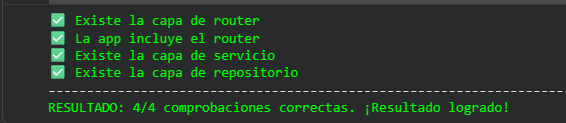